<a href="https://colab.research.google.com/github/poojakesarkar27/CSL701-CS24_Machine-Learning-Lab/blob/experiments-ml/ML_Experiment_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

 ML Experiment Number 10


Student Name :Pooja Rupesh Kesarkar

Batch :CS 02


Roll Number :CS24



### **Aim**

To implement DBSCAN clustering using Python for customer segmentation on the Mall Customer Segmentation dataset and identify arbitrary-shaped clusters along with spatial outliers (noise).

## Objectives

1. To understand the principles of Density-Based Spatial Clustering of Applications with Noise (DBSCAN).
2. To implement DBSCAN clustering using Python.3. To preprocess and feature-scale tabular customer data using StandardScaler.
4. To determine optimal hyperparameters ($\varepsilon$ and $min\_samples$) using $k$-distance graph analysis.
5. To identify core points, border points, and spatial outliers (noise points denoted by label $-1$).
6. To evaluate clustering performance using metrics like Silhouette Score.

# Relevant Theory

###DBSCAN (Density-Based Spatial Clustering of Applications with Noise)
DBSCAN is an unsupervised non-parametric clustering algorithm that groups data points based on local density estimations. Unlike centroid-based algorithms (e.g., K-Means), DBSCAN can discover arbitrary-shaped clusters and automatically isolate noisy data points without requiring the user to specify the total number of clusters in advance.

Core Concepts and Parameters:

1. $\varepsilon$ (Epsilon): The maximum radius of the neighborhood around a given data point $x$.
2. $min\_samples$ (MinPts): The minimum number of points within the $\varepsilon$-neighborhood required to form a dense region.

Point ClassificationsCore Point:
* A point that has at least $min\_samples$ within its $\varepsilon$-neighborhood.
* Border Point: A point that is within the $\varepsilon$-neighborhood of a Core Point but has fewer than $min\_samples$ in its own neighborhood.
* Noise Point (Outlier): A point that is neither a Core Point nor a Border Point. Noise points are assigned a cluster label of $-1$.

###Dataset Information
Get the Mall Customer Segmentation dataset from Kaggle using the following link:
https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python

The dataset contains spending patterns and demographic attributes of mall customers:

* CustomerID: Unique identifier for each customer.

* Gender: Male or Female.

* Age: Age of the customer.

* Annual Income (k$): Annual income of the customer in thousands of dollars.

* Spending Score (1-100): Score assigned based on customer behavior and purchasing patterns.

For clustering, we will use: Annual Income (k$) and Spending Score (1-100).

# Task 1: Import Libraries and Load Dataset
* Load essential libraries (numpy, pandas, matplotlib, seaborn, sklearn).

* Load the Mall Customer Segmentation dataset (Mall_Customers.csv).
---

In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score

# Upload dataset
uploaded = files.upload()
filename = next(iter(uploaded))

df = pd.read_csv(filename)

print("Dataset loaded successfully!")
print(df.head())
print("\nDataset Shape:", df.shape)
print("\nColumn Names:", df.columns.tolist())
print("\nMissing Values:\n", df.isnull().sum())


Saving Mall_Customers.csv to Mall_Customers.csv
Dataset loaded successfully!
   CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)
0           1    Male   19                  15                      39
1           2    Male   21                  15                      81
2           3  Female   20                  16                       6
3           4  Female   23                  16                      77
4           5  Female   31                  17                      40

Dataset Shape: (200, 5)

Column Names: ['CustomerID', 'Gender', 'Age', 'Annual Income (k$)', 'Spending Score (1-100)']

Missing Values:
 CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64


# Task 2: Feature Selection and Standardization

* Select target features (Annual Income ($k$) and Spending Score (1-100)).
* Scale features using Standard Scaler to bring feature dimensions to a comparable range ($\mu=0, \sigma=1$), which is crucial for distance-based neighborhood computations.

In [ ]:

# Select features
features = ["Annual Income (k$)", "Spending Score (1-100)"]

X = df[features].copy()

# Handle missing values if present
X = X.fillna(X.median())

# Standardize features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Selected Features:", features)
print("\nFirst 5 Standardized Records:")
print(X_scaled[:5])

print("\nFeature Means:", X_scaled.mean(axis=0))
print("Feature Standard Deviations:", X_scaled.std(axis=0))


Selected Features: ['Annual Income (k$)', 'Spending Score (1-100)']

First 5 Standardized Records:
[[-1.73899919 -0.43480148]
 [-1.73899919  1.19570407]
 [-1.70082976 -1.71591298]
 [-1.70082976  1.04041783]
 [-1.66266033 -0.39597992]]

Feature Means: [-2.13162821e-16 -1.46549439e-16]
Feature Standard Deviations: [1. 1.]


# Task 3: Hyperparameter Selection via $k$-Distance Graph

* Compute Nearest Neighbors using NearestNeighbors ($k = min\_samples$).
* Plot sorted $k$-distances to locate the "elbow point," which indicates the optimal value for $\varepsilon$ (Epsilon).

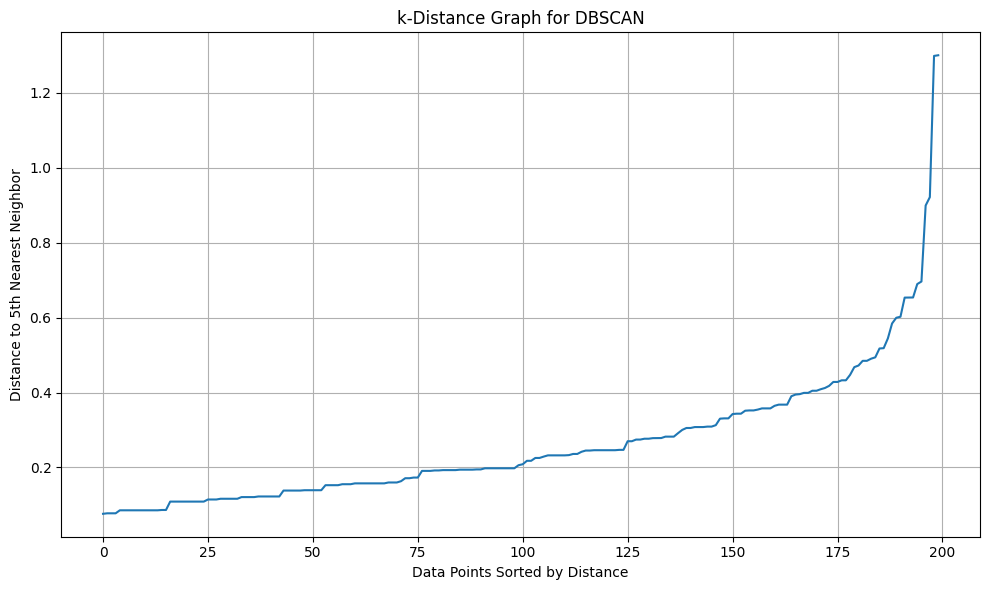

In [ ]:

# Choose min_samples
min_samples = 5

# Calculate distances to nearest neighbors
neighbors = NearestNeighbors(n_neighbors=min_samples)
neighbors.fit(X_scaled)

distances, indices = neighbors.kneighbors(X_scaled)

# Sort distances to the kth nearest neighbor
k_distances = np.sort(distances[:, min_samples - 1])

# Plot k-distance graph
plt.figure(figsize=(10, 6))
plt.plot(k_distances)
plt.xlabel("Data Points Sorted by Distance")
plt.ylabel(f"Distance to {min_samples}th Nearest Neighbor")
plt.title("k-Distance Graph for DBSCAN")
plt.grid(True)
plt.tight_layout()
plt.show()


# Task 4: Implement DBSCAN Clustering

* Instantiate sklearn.cluster.DBSCAN with the identified $\varepsilon$ and $min\_samples$.
* Fit the model on scaled data to generate cluster assignments and noise labels ($-1$).

In [ ]:

# Set DBSCAN parameters
eps_value = 0.3

dbscan = DBSCAN(
    eps=eps_value,
    min_samples=min_samples
)

# Fit the model
cluster_labels = dbscan.fit_predict(X_scaled)

# Append cluster labels to dataset
df["Cluster"] = cluster_labels

print("DBSCAN clustering completed!")
print("\nCluster Labels:")
print(np.unique(cluster_labels))
print("\nFirst 10 Cluster Assignments:")
print(df[["CustomerID", "Annual Income (k$)",
          "Spending Score (1-100)", "Cluster"]].head(10))


DBSCAN clustering completed!

Cluster Labels:
[-1  0  1  2  3  4  5  6]

First 10 Cluster Assignments:
   CustomerID  Annual Income (k$)  Spending Score (1-100)  Cluster
0           1                  15                      39        2
1           2                  15                      81        0
2           3                  16                       6        1
3           4                  16                      77        0
4           5                  17                      40        2
5           6                  17                      76        0
6           7                  18                       6        1
7           8                  18                      94       -1
8           9                  19                       3        1
9          10                  19                      72        0


# Task 5: Evaluate DBSCAN Clustering

* Cluster Count: Calculate the number of clusters generated (excluding noise points).
* Noise Point Analysis: Count and evaluate identified spatial outliers (label $-1$).
* Silhouette Score: Calculate Silhouette Score to evaluate cluster cohesion and separation.

In [ ]:

# Count clusters, excluding noise (-1)
n_clusters = len(set(cluster_labels) - {-1})

# Count noise points
n_noise = np.sum(cluster_labels == -1)

print("Number of Clusters:", n_clusters)
print("Number of Noise Points:", n_noise)
print("Percentage of Noise Points:",
      round(n_noise / len(cluster_labels) * 100, 2), "%")

# Silhouette score requires at least 2 clusters
non_noise_mask = cluster_labels != -1
non_noise_labels = cluster_labels[non_noise_mask]
non_noise_data = X_scaled[non_noise_mask]

if len(np.unique(non_noise_labels)) >= 2:
    score = silhouette_score(non_noise_data, non_noise_labels)
    print("Silhouette Score (excluding noise):", round(score, 4))
else:
    print("Silhouette Score cannot be calculated: "
          "fewer than 2 non-noise clusters detected.")


Number of Clusters: 7
Number of Noise Points: 35
Percentage of Noise Points: 17.5 %
Silhouette Score (excluding noise): 0.5243


# Task 6: Analyze Results and Cluster Statistics
* Extract cluster labels and append them back to the original dataset.

* Calculate mean statistics (e.g., average Annual Income and Spending Score) per cluster to interpret final customer segments and evaluate detected noise points.

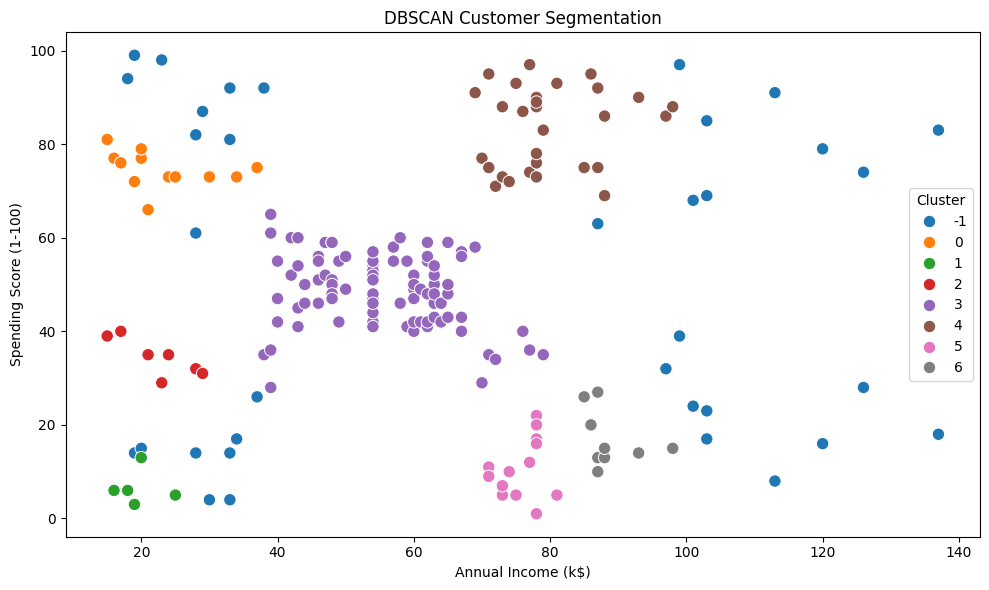

In [ ]:

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="Annual Income (k$)",
    y="Spending Score (1-100)",
    hue="Cluster",
    palette="tab10",
    s=80
)

plt.title("DBSCAN Customer Segmentation")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()


In [ ]:

# Mean income and spending score for each cluster
cluster_stats = df.groupby("Cluster").agg(
    Customer_Count=("CustomerID", "count"),
    Average_Annual_Income=("Annual Income (k$)", "mean"),
    Average_Spending_Score=("Spending Score (1-100)", "mean")
).round(2)

print("Cluster Statistics:")
print(cluster_stats)

# Separate noise points
noise_customers = df[df["Cluster"] == -1]

print("\nNumber of Noise Customers:", len(noise_customers))
print("\nNoise Customer Records:")
print(noise_customers.head(10))


Cluster Statistics:
         Customer_Count  Average_Annual_Income  Average_Spending_Score
Cluster                                                               
-1                   35                  70.60                   51.66
 0                   12                  23.17                   74.58
 1                    5                  19.60                    6.60
 2                    7                  22.43                   34.43
 3                   88                  55.23                   48.58
 4                   30                  79.53                   83.13
 5                   14                  75.93                   10.07
 6                    9                  88.78                   17.00

Number of Noise Customers: 35

Noise Customer Records:
    CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)  \
7            8  Female   23                  18                      94   
10          11    Male   67                  19                 

# Conclusion

The experiment successfully implemented DBSCAN clustering on the Mall Customer Segmentation dataset. Feature standardization ensured balanced neighborhood distance calculations across income and spending metrics. By analyzing $k$-distance graphs, optimal $\varepsilon$ and $min\_samples$ parameters were selected, enabling the discovery of density-defined customer segments and explicit identification of spatial noise points (outliers) without requiring a pre-defined cluster count.